In [2]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib
import os

In [3]:
df = pd.read_csv("../data/processed/sales_features.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(["date", "store", "item"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (899000, 17)
        date  store  item  sales  year  month  day  day_of_week  week_of_year  \
0 2013-01-29      1     1      6  2013      1   29            1             5   
1 2013-01-29      1     2     35  2013      1   29            1             5   
2 2013-01-29      1     3     15  2013      1   29            1             5   
3 2013-01-29      1     4     13  2013      1   29            1             5   
4 2013-01-29      1     5      9  2013      1   29            1             5   

   quarter  is_weekend  lag_1  lag_7  lag_14  lag_28  rolling_mean_7  \
0        1           0   11.0    7.0     5.0    13.0       10.428571   
1        1           0   16.0   29.0    27.0    33.0       27.571429   
2        1           0   14.0   20.0    12.0    15.0       17.571429   
3        1           0    7.0   11.0    14.0    10.0        9.000000   
4        1           0    9.0    9.0    10.0    11.0        9.428571   

   rolling_mean_28  
0        10.714286  
1        2

In [4]:
# Define features and target
features = [
    "store", "item",
    "year", "month", "day", "day_of_week",
    "week_of_year", "quarter", "is_weekend",
    "lag_1", "lag_7", "lag_14", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

target = "sales"

X = df[features]
y = df[target]

In [5]:
# Chronological split
# Use exactly the same date ranges as your baseline experiment.
train = df[df["date"] <= "2016-12-31"]
validation = df[
    (df["date"] >= "2017-01-01") &
    (df["date"] <= "2017-06-30")
]
test = df[
    (df["date"] >= "2017-07-01") &
    (df["date"] <= "2017-12-31")
]

X_train = train[features]
y_train = train[target]

X_val = validation[features]
y_val = validation[target]

X_test = test[features]
y_test = test[target]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (716500, 15)
Validation: (90500, 15)
Testing: (92000, 15)


In [6]:
# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=1.0,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [7]:
# Evaluate the model
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (
        np.sum(np.abs(actual - predicted)) /
        np.sum(np.abs(actual))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }

val_predictions = rf_model.predict(X_val)
test_predictions = rf_model.predict(X_test)

print("Validation Results:")
print(evaluate_model(y_val, val_predictions))

print("\nTest Results:")
print(evaluate_model(y_test, test_predictions))

Validation Results:
{'MAE': 6.087062983040209, 'RMSE': np.float64(7.930229922803644), 'WAPE': np.float64(10.83232098004526)}

Test Results:
{'MAE': 6.453024913991605, 'RMSE': np.float64(8.39249221030422), 'WAPE': np.float64(10.51088062140622)}


In [8]:
# sae the model
os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.


In [9]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

importance.to_csv(
    "../reports/random_forest_feature_importance.csv",
    index=False
)

            Feature  Importance
13   rolling_mean_7    0.680733
10            lag_7    0.228091
11           lag_14    0.024232
9             lag_1    0.018337
5       day_of_week    0.016582
14  rolling_mean_28    0.011870
12           lag_28    0.004658
4               day    0.004182
6      week_of_year    0.004098
3             month    0.003363
1              item    0.001484
8        is_weekend    0.000913
0             store    0.000890
2              year    0.000477
7           quarter    0.000090


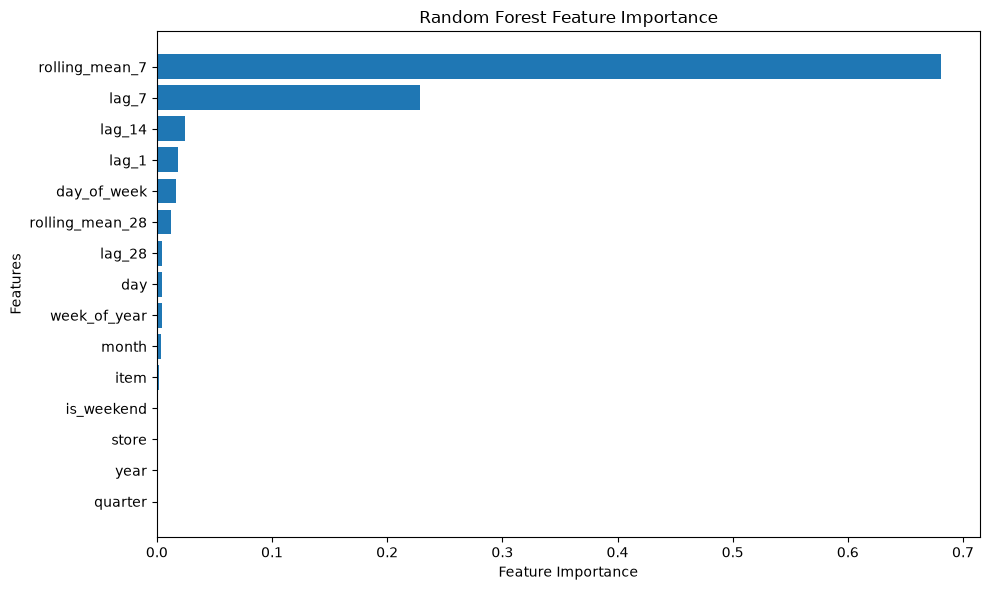

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [11]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

['../models/random_forest_model.pkl']